# Baselines: how far do existing models get before we train anything?

Before we train our own snake identifier, we ask a plain question: what do models that already exist
score on our validation photos? Every trained model later has to beat these numbers, so they are its
floor. We try six baselines, from a model that never looks at the photo to a published snake
identifier. We also measure how well a class can be learned from only a handful of photos (few-shot).

The notebook needs our cleaned snake photos, the 16% experiment subset and a small set of Open Images
snake boxes, all fetched from Kaggle datasets. It also downloads the published SnakeCLEF 2021 model and
BioCLIP from the internet. It writes one folder per baseline under `baselines/` with its scores, a
`comparison.csv`, and the few-shot results under `fewshot/`. Run it on a Kaggle T4 GPU with internet on;
it takes three to four hours.

## The baselines in plain words

| Name | What it does | Looks at the photo? |
|---|---|---|
| B0 | Always answers with the most common species, in proportion to the subset | no |
| B1 | A snake identifier published in 2022 (Bolon et al.), with its labels mapped to our species | yes |
| B2 | BioCLIP, a general biology model, asked to match each photo to "a photo of <species>" | yes |
| B3 | Three small image encoders with ImageNet weights, frozen, scored by the nearest class average | yes |
| B4 | DINOv2, a frozen general-purpose encoder, with a simple classifier on top (a linear probe) | yes |
| B5 | A detector trained on Open Images, used as is to find snakes (boxes, not species) | yes |

B1 and B2 may have seen our validation photos while they were trained, so their full-validation score
is an upper bound. For B1 we also score the photos uploaded from 2022, after its training data ends.

## Setup

One cell installs the few libraries this notebook needs (versions pinned), silences download chatter,
and picks Kaggle or local paths.

In [1]:
%pip uninstall -q -y onnxruntime
%pip install -q timm==1.0.31 albumentations==2.0.8 scikit-learn==1.9.1 open_clip_torch==2.32.0
%pip install -q onnx==1.23.2 onnxruntime-gpu==1.31.1 ultralytics==8.4.202

import os, warnings
os.environ.update(NO_ALBUMENTATIONS_UPDATE="1", YOLO_VERBOSE="False",
                  HF_HUB_DISABLE_PROGRESS_BARS="1", TQDM_DISABLE="1")
warnings.filterwarnings("ignore")

import hashlib, json, shutil, sys, time, urllib.request
from pathlib import Path
import kagglehub, matplotlib.pyplot as plt, numpy as np, pandas as pd, torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset

ON_KAGGLE = Path("/kaggle/working").exists()  # False on a laptop, which uses ./work instead
OUT = Path("/kaggle/working/baselines" if ON_KAGGLE else "work/baselines")
FEWSHOT_OUT = OUT.parent / "fewshot"
# the 1.1 GB model is kept out of the notebook output
DOWNLOADS = Path("/kaggle/tmp/baselines" if ON_KAGGLE else "work/downloads")
CODE = Path("/kaggle/input/serpentguard-code/src")
if not CODE.exists():
    CODE = Path("../src").resolve()  # running from the repo's notebooks/ folder
sys.path.insert(0, str(CODE))

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Our photos and the subset

We read the cleaned metadata and the 16% subset that every trained model learns from. The subset's
fingerprint is checked so we know the baselines see the same photos. `train` is the subset after the
per-class caps, `val` is the validation split, and `calibration` is a held-back set of photos from
other photographers. `settings["limit"]` set to a number gives a quick smoke run.

In [2]:
from serpentguard.data import ID_TYPES, SnakeDataset, build_frame, cap_train, load_rgb, with_files
from serpentguard.metrics import class_tables, softmax, write_json

settings = dict(batch=64, workers=os.cpu_count() or 2, limit=None, seed=42,
                subset_hash="40196d19a68e", slice_photos=13_947)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for folder in (OUT, FEWSHOT_OUT, DOWNLOADS):
    folder.mkdir(parents=True, exist_ok=True)

def dataset_path(name):
    return Path(kagglehub.dataset_download(f"puneetbajajiitm/{name}"))

DATA = dataset_path("serpentguard-indian-snakes-clean")
SUBSET = dataset_path("serpentguard-m3-subset") / "subset.csv"
EXTENDED = dataset_path("serpentguard-extended-sources")

Then the tables and the three frames.

In [3]:
metadata = pd.read_csv(DATA / "metadata.csv", dtype=ID_TYPES, low_memory=False)
classes = pd.read_csv(DATA / "classes.csv")
subset = pd.read_csv(SUBSET, dtype=ID_TYPES)
digest = hashlib.sha256("\n".join(sorted(subset["path"])).encode()).hexdigest()
assert digest.startswith(settings["subset_hash"]), f"another subset was read: {digest}"

def cut(frame):  # a smoke run keeps the first N photos
    frame = frame.reset_index(drop=True)
    return frame if settings["limit"] is None else frame.head(settings["limit"])

all_train = metadata[metadata["split"] == "train"]
in_subset = all_train["path"].isin(subset["path"])
spare = all_train[~in_subset & ~all_train["observer_id"].isin(subset["observer_id"])]
train = with_files(cut(cap_train(build_frame(all_train[in_subset], classes, ["train"]))), DATA)
val = with_files(cut(build_frame(metadata, classes, ["val"])), DATA)
calibration = with_files(cut(build_frame(spare, classes, ["train"])), DATA)

## How every baseline is scored

Every baseline, and later our own trained model, goes through the two functions below, so all scores
are comparable. `upload_2022_slice` marks the validation photos uploaded on or after 1 January 2022
(compared as text on the metadata's `created_at`). `summary_row` flattens a result into one row of
the comparison table at the end. `baseline_metrics` takes a table of probabilities,
one row per validation photo and one column per species, and returns the same report our training
runs write: species scores (`head`, and `prototype` where a baseline has one), safety, calibration
and taxonomy. It reports the whole validation set and the 2022 slice. The slice keeps the classes
that are measurable on the whole set, so the two are comparable.

In [4]:
import math
import numpy as np
from serpentguard.metrics import calibration as calibration_scores
from serpentguard.metrics import safety_report, species_report, taxonomy_report

PATH, CLASS_ID, UPLOAD_2022 = "path", "class_id", "upload_2022_slice"  # names other scripts read
SLICE_UPLOADED_FROM = "2022-01-01"  # created_at is compared as text

def upload_2022_slice(frame, metadata, uploaded_from=SLICE_UPLOADED_FROM):
    """True for each frame row whose photo was uploaded on or after uploaded_from."""
    created = frame[[PATH]].merge(metadata[[PATH, "created_at"]], on=PATH, how="left",
                                  indicator=True, validate="many_to_one")
    assert created["_merge"].ne("left_only").all(), "some photos are missing from metadata"
    return created["created_at"].fillna("").astype(str).ge(uploaded_from).to_numpy()

def baseline_metrics(val, probs, train_counts, taxa, in_slice, run, evaluation="full_validation",
                     slice_overlap="no labelled photos from outside our training subset",
                     prototype_probs=None, extra=None):
    """The scores of one table of probabilities, on full validation and on the 2022 upload slice."""
    y_true = val[CLASS_ID].to_numpy()
    val_counts = np.bincount(y_true, minlength=taxa.n_classes)
    genus, family = val["genus_id"].to_numpy(), val["family_id"].to_numpy()
    in_slice = np.asarray(in_slice, dtype=bool)
    def scored(rows):
        def species(p):
            return species_report(y_true[rows], p[rows], train_counts, val_counts, taxa.tier)
        report = {"head": species(probs)}
        if prototype_probs is not None:
            report["prototype"] = species(prototype_probs)
        report["safety"] = safety_report(y_true[rows], probs[rows], taxa.who,
                                         taxa.listed_or_venomous)
        report["calibration"] = calibration_scores(probs[rows], y_true[rows])
        report["taxonomy"] = taxonomy_report(probs[rows], None, None, taxa.genus_of_class,
                                             taxa.family_of_class, genus[rows], family[rows])
        return report

    slice_report = {"label": UPLOAD_2022, "overlap": slice_overlap, "photos": int(in_slice.sum()),
                    "classes": int(np.unique(y_true[in_slice]).size), **scored(in_slice)}
    return {**scored(np.ones(len(y_true), dtype=bool)), UPLOAD_2022: slice_report, **(extra or {}),
            "run": {**run, "evaluation": evaluation, "val_photos": len(y_true)}}

def summary_row(name, final):
    """One comparison row from a final_metrics.json; numbers it lacks are nan."""
    columns = {"macro_f1": "head.macro_f1", "macro_f1_prototype": "prototype.macro_f1",
               "top1": "head.top1", "top3": "head.top3", "who_recall": "safety.who_recall_raw",
               "o3_raw": "safety.top1_error_raw", "ece": "calibration.ece",
               "macro_f1_2022": f"{UPLOAD_2022}.head.macro_f1",
               "top1_2022": f"{UPLOAD_2022}.head.top1", "slice_overlap": f"{UPLOAD_2022}.overlap",
               "class_coverage": "coverage.class_share", "photo_coverage": "coverage.photo_share",
               "precision": "detection.precision", "recall": "detection.recall",
               "map50": "detection.map50"}

    def pick(path):
        value = final
        for key in path.split("."):
            value = value.get(key, math.nan) if isinstance(value, dict) else math.nan
        return value

    evaluation = final.get("run", {}).get("evaluation", "full_validation")
    return {"model": name, "evaluation": evaluation, **{c: pick(p) for c, p in columns.items()}}

Now we apply that to our data: the per-species training counts, which validation photos fall in the
2022 slice, and a table of how big each part is.

In [5]:
taxa = class_tables(classes)
train_counts = np.bincount(train["class_id"], minlength=taxa.n_classes)
in_2022 = upload_2022_slice(val, metadata)
if settings["limit"] is None:
    assert in_2022.sum() == settings["slice_photos"], f"{in_2022.sum()} validation photos from 2022"

RUN = {"subset_hash": digest, "train_photos": len(train), "device": str(DEVICE),
       "limit": settings["limit"],
       "config": {"frame_config": "whole photo, no masks", "frame_input_size": 320,
                  "slice_uploaded_from": SLICE_UPLOADED_FROM, **settings}}
sizes = pd.DataFrame({"photos": [len(train), len(val), int(in_2022.sum()), len(calibration)],
                      "species": [train["class_id"].nunique(), val["class_id"].nunique(),
                                  val["class_id"][in_2022].nunique(),
                                  calibration["class_id"].nunique()]},
                     index=["train (capped subset)", "validation", "validation, uploaded from 2022",
                            "calibration"])
sizes

,photos,species
train (capped subset),13611,184
validation,17151,176
"validation, uploaded from 2022",13947,174
calibration,7999,111


Each baseline saves its scores the same way: `final_metrics.json`, `versions.json` and, where there are
per-photo predictions, `predictions.npz`, all in `baselines/<name>/`. The `save` function below writes
them and prints the non-empty summary numbers.

In [6]:
import cv2, sklearn, timm
import albumentations

LIBRARIES = {"python": sys.version.split()[0], "torch": torch.__version__, "timm": timm.__version__,
             "albumentations": albumentations.__version__, "numpy": np.__version__,
             "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
             "opencv": cv2.__version__, "cuda": torch.version.cuda}

def save(name, metrics, outputs=None, extra_versions=None):
    """Write a baseline's files under OUT/name and print its non-empty summary numbers."""
    folder = OUT / name
    folder.mkdir(parents=True, exist_ok=True)
    write_json(folder / "versions.json", {**LIBRARIES, **(extra_versions or {})})
    if outputs:
        def text(column):
            return val[column].astype("string").fillna("").to_numpy(dtype=str)

        number = {name: val[name].to_numpy() for name in
                  ("genus_id", "family_id", "who_risk_id")}
        np.savez_compressed(folder / "predictions.npz", paths=text("path"),
                            labels=val["class_id"].to_numpy(), species=text("species"),
                            observer_id=text("observer_id"), **number, **outputs)
    saved = write_json(folder / "final_metrics.json", metrics)
    print({key: round(v, 4) if isinstance(v, float) else v
           for key, v in summary_row(name, saved).items() if v == v})
    return saved

## B0: the class-frequency prior

B0 ignores the photo. Every validation photo gets the same probabilities: how common each species is
in the training subset. It shows what a model scores by knowing nothing about snakes except how often
each species appears. Its macro-F1 should sit near zero.

In [7]:
probs = np.tile(train_counts / train_counts.sum(), (len(val), 1))
run = {**RUN, "run_id": "B0", "baseline": "class frequencies of the capped subset"}
save("B0", baseline_metrics(val, probs, train_counts, taxa, in_2022, run))

{'model': 'B0', 'evaluation': 'full_validation', 'macro_f1': 0.0011, 'top1': 0.0945, 'top3': 0.2183, 'who_recall': 0.0, 'o3_raw': 1.0, 'ece': 0.021, 'macro_f1_2022': 0.0011, 'top1_2022': 0.0911, 'slice_overlap': 'no labelled photos from outside our training subset'}


{'head': {'macro_f1': 0.0010958070676513833,
  'macro_f1_tier1': 0.003091741369444974,
  'macro_f1_tier2': 0.0,
  'macro_f1_band': {'<30': 0.0, '30-99': 0.0, '100+': 0.004946786191111959},
  'pooled_recall_rare': 0.0,
  'top1': 0.09451343944959478,
  'top3': 0.21829630925310478,
  'balanced_acc': 0.005681818181818182,
  'per_class': {'0': {'precision': 0.09451343944959478,
    'recall': 1.0,
    'f1': 0.17270402727466438,
    'support': 1621},
   '1': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 1167},
   '2': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 956},
   '3': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 724},
   '4': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 642},
   '5': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 728},
   '6': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 510},
   '7': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support': 472},
   '8': {'precision': nan, 'recall': 0.0, 'f1': 0.0, 'support

## B1: the published SnakeCLEF 2021 model

B1 is the global snake identifier of Bolon et al. (2022), a ViT-Large that sees 772 species. The model
and its list of labels come from the LINDAT repository (item `20.500.12800/1-4773`, BSD-3 licence). We
read the file addresses and MD5 checksums from the item page saved on 22 October 2026, and the download
checks each checksum. The labels are the SnakeCLEF 2021 training metadata's `class_id` to `binomial`
pairs. The model has to be fed exactly as it was trained, so the next cells show what its graph does
with a photo before we trust anything it says.

In [8]:
LINDAT = ("https://lindat.mff.cuni.cz/repository/server/api/core/bitstreams/handle/"
          "20.500.12800/1-4773")
MODEL_FILE = "ViT_PreProcessing-ops11-preprocessing-int-dynam_graph.onnx?sequence=7&isAllowed=y"
B1_FILES = {  # name: (url, expected MD5)
    "model": (f"{LINDAT}/{MODEL_FILE}", "838ae0f8ed19ffeee89aba5fa8b50956"),
    "labels": (f"{LINDAT}/min-train_metadata.csv?sequence=2&isAllowed=y",
               "52ec43c8595a3835da6aa16364aff75e"),
}

def download(url, path, md5):
    """Fetch a file once, then check its MD5."""
    if not path.exists():
        partial = path.with_name(path.name + ".part")
        with urllib.request.urlopen(url, timeout=120) as response, open(partial, "wb") as out:
            shutil.copyfileobj(response, out, 2 ** 24)
        partial.rename(path)
    digest = hashlib.md5()
    with open(path, "rb") as stored:
        for chunk in iter(lambda: stored.read(2 ** 24), b""):
            digest.update(chunk)
    assert digest.hexdigest() == md5, f"{path.name}: MD5 {digest.hexdigest()}, expected {md5}"
    return path

(model_url, model_md5), (labels_url, labels_md5) = B1_FILES["model"], B1_FILES["labels"]
b1_model = download(model_url, DOWNLOADS / "bolon_vit.onnx", model_md5)
b1_labels_file = download(labels_url, DOWNLOADS / "snakeclef_min_train_metadata.csv", labels_md5)
print(f"model {b1_model.stat().st_size / 1e9:.2f} GB, MD5 checked")

model 1.22 GB, MD5 checked


In [9]:
import onnx, onnxruntime
onnxruntime.disable_telemetry_events()
available = onnxruntime.get_available_providers()
providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in available]
session = onnxruntime.InferenceSession(str(b1_model), providers=providers)
for spec in session.get_inputs() + session.get_outputs():
    print(f"{spec.name}: shape {spec.shape}, {spec.type}")
n_outputs = session.get_outputs()[0].shape[-1]
assert isinstance(n_outputs, int), f"the output width is {n_outputs!r}, not a fixed number"

ops = [node.op_type for node in onnx.load(str(b1_model)).graph.node]
first_conv = ops.index("Conv") if "Conv" in ops else len(ops)
resizes = any(op in ("Resize", "Upsample") for op in ops[:first_conv])
print(f"{len(ops)} nodes; resizes its input itself: {resizes}; first operations: {ops[:20]}")
assert resizes, "the graph does not size its own input: read an input size from the printout"

input: shape ['?', '?', 3], tensor(int32)
output: shape [1, 772], tensor(float)
2404: shape [1, 772], tensor(float)
1909 nodes; resizes its input itself: True; first operations: ['Cast', 'Transpose', 'Unsqueeze', 'Constant', 'Div', 'Shape', 'Constant', 'Constant', 'Constant', 'Slice', 'Concat', 'Constant', 'Constant', 'Resize', 'Constant', 'Sub', 'Constant', 'Div', 'Cast', 'Conv']


The graph takes a whole photo at its own size and resizes it inside. Its 772 outputs are numbered, and
the number is not our class id, so we rebuild the label list from the training metadata. An output
number with no photo in that metadata has no name.

In [10]:
meta = pd.read_csv(b1_labels_file, low_memory=False)
pairs = meta[["class_id", "binomial"]].dropna().drop_duplicates()
assert (pairs.groupby("class_id")["binomial"].nunique() <= 1).all(), "a class id has two names"
assert pairs["class_id"].between(0, n_outputs - 1).all(), "a class id lies outside the outputs"
b1_labels = [None] * n_outputs
for class_id, name in zip(pairs["class_id"].astype(int), pairs["binomial"].astype(str)):
    b1_labels[class_id] = name
unnamed = sum(name is None for name in b1_labels)
print(f"{n_outputs} outputs, {unnamed} without a name; e.g. {[n for n in b1_labels if n][:8]}")

772 outputs, 4 without a name; e.g. ['Acanthophis antarcticus', 'Acanthophis hawkei', 'Acanthophis praelongus', 'Acanthophis pyrrhus', 'Acanthophis rugosus', 'Acanthophis wellsi', 'Achalinus formosanus', 'Achalinus niger']


### Mapping their species to ours

Names match when they agree after ignoring case, underscores and spacing. Some species were renamed
since 2021, so a short list of synonyms maps the older name to the one in our `classes.csv`. Species
that B1 does not know can never be predicted, so their photos count as misses.

In [11]:
SYNONYMS = {  # older names a published model may use -> the name in our classes.csv
    "Xenochrophis piscator": "Fowlea piscator",
    **{f"Trimeresurus {e}": f"Craspedocephalus {e}"
       for e in ("malabaricus", "gramineus", "anamallensis", "travancoricus", "macrolepis")},
    "Macropisthodon plumbicolor": "Rhabdophis plumbicolor",
    "Ramphotyphlops braminus": "Indotyphlops braminus",
}

def normalise(name):
    return " ".join(str(name).replace("_", " ").split()).lower()

def map_labels(their_names, our_species):
    """For each of their labels, our class id, or -1; also the renamed species."""
    ours = {normalise(name): i for i, name in enumerate(our_species)}
    renames = {normalise(old): normalise(new) for old, new in SYNONYMS.items()}
    index_map, renamed = np.full(len(their_names), -1), {}
    for i, name in enumerate(their_names):
        key = normalise(name) if name is not None else None
        if key in ours:
            index_map[i] = ours[key]
        elif renames.get(key) in ours:
            index_map[i] = ours[renames[key]]
            renamed[name] = str(our_species[index_map[i]])
    return index_map, renamed

How many of our species does B1 know, and how many validation photos do they cover?

In [12]:
index_map, renamed = map_labels(b1_labels, list(taxa.species))
covered_ids = sorted(set(index_map[index_map >= 0].tolist()))
coverage = {"classes": len(taxa.species), "classes_covered": len(covered_ids),
            "class_share": len(covered_ids) / len(taxa.species), "covered_class_ids": covered_ids,
            "uncovered_species": [s for i, s in enumerate(taxa.species)
                                  if i not in set(covered_ids)],
            "their_labels": n_outputs, "their_labels_mapped": int((index_map >= 0).sum()),
            "their_labels_unnamed": unnamed, "renamed": renamed,
            "photos": len(val), "photo_share": float(val["class_id"].isin(covered_ids).mean()),
            "photo_share_upload_2022_slice":
                float(val["class_id"][in_2022].isin(covered_ids).mean())}
print(f"B1 knows {coverage['classes_covered']} of our {coverage['classes']} species, "
      f"{coverage['photo_share']:.1%} of validation photos; renamed: {renamed}")

B1 knows 62 of our 184 species, 85.2% of validation photos; renamed: {'Macropisthodon plumbicolor': 'Rhabdophis plumbicolor', 'Trimeresurus gramineus': 'Craspedocephalus gramineus', 'Trimeresurus malabaricus': 'Craspedocephalus malabaricus', 'Xenochrophis piscator': 'Fowlea piscator'}


### Feeding the photos in

The model's authors document their input in the code repository `picekl/PlosNTD-GlobalSnakeID`
(README and the SnakeCLEF 2021 ViT-Large/16 notebook, read 5 November 2026): 384 x 384 pixels,
resized without keeping the aspect ratio, the usual timm mean and standard deviation, photos read
with OpenCV and turned from BGR to RGB. The graph does the resizing and normalising itself, so we pass
each photo as 0-255 pixel values, one photo per run, in the graph's own number type. Then we turn the
model's probabilities over its 772 labels into probabilities over our 184 species.

In [13]:
input_spec = session.get_inputs()[0]
input_dtype = {"tensor(uint8)": np.uint8, "tensor(int32)": np.int32, "tensor(int64)": np.int64,
               "tensor(float)": np.float32, "tensor(float16)": np.float16}[input_spec.type]

class LoadedPhotos(Dataset):
    """Photos read as training reads them (exposure fix included), in the graph's number type."""
    def __init__(self, paths, channel_order):
        self.paths, self.channel_order = list(paths), channel_order

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        pixels = load_rgb(self.paths[i]).astype(np.float32)
        pixels = pixels[..., ::-1] if self.channel_order == "BGR" else pixels
        return np.ascontiguousarray(pixels.astype(input_dtype))

The function that runs B1 on a table of photos and returns probabilities over our species.

In [14]:
def b1_probs(frame, channel_order="RGB", report_every=None):
    """B1's probabilities over our classes; a photo with no mapped mass gets a flat spread."""
    loader = DataLoader(LoadedPhotos(frame["image_file"], channel_order), batch_size=None,
                        num_workers=settings["workers"])
    scores, started = [], time.perf_counter()
    for item in loader:
        raw = session.run([session.get_outputs()[0].name], {input_spec.name: item.numpy()})[0]
        scores.append(np.asarray(raw).reshape(-1, n_outputs))
        if report_every and len(scores) % report_every == 0:
            speed = len(scores) / (time.perf_counter() - started)
            print(f"{len(scores)}/{len(frame)} photos, {speed:.1f}/s", flush=True)
    scores = np.concatenate(scores).astype(np.float64)
    is_probability = (scores >= 0).all() and np.allclose(scores.sum(axis=1), 1, atol=1e-3)
    theirs = scores if is_probability else softmax(scores)
    mapped = index_map >= 0
    probs = theirs[:, mapped] @ np.eye(len(taxa.species))[index_map[mapped]]
    flat = np.zeros(len(taxa.species))
    flat[covered_ids] = 1
    probs[probs.sum(axis=1) <= 0] = flat
    return probs / probs.sum(axis=1, keepdims=True)

### A check before the long run

Two mistakes would silently ruin B1: a label list in the wrong order, or the colour channels the wrong
way round. We score 256 validation photos of species B1 knows. The right setup must beat a floor (20%, or
ten times chance if that is lower), and swapping the channels must not do noticeably better.

In [15]:
check = val[val["class_id"].isin(covered_ids)]
check = check.sample(min(256, len(check)), random_state=42)
top1 = {order: float((b1_probs(check, order).argmax(axis=1) == check["class_id"].to_numpy()).mean())
        for order in ("RGB", "BGR")}
chance = 1 / len(covered_ids)
threshold = min(0.2, 10 * chance)
print(f"top-1 on {len(check)} photos of covered species: RGB {top1['RGB']:.3f}, "
      f"BGR {top1['BGR']:.3f} (needs {threshold:.3f}; chance {chance:.4f})")
assert top1["RGB"] >= threshold, "below the floor: check the label order, then the input"
assert top1["BGR"] <= top1["RGB"] + 0.05, "swapped channels score higher: check the channel order"
label_order_check = {"top1": top1["RGB"], "threshold": threshold, "chance": chance,
                     "photos": len(check)}

top-1 on 256 photos of covered species: RGB 0.820, BGR 0.613 (needs 0.161; chance 0.0161)


Now the full validation set, one photo at a time (about 15 to 25 photos per second on a T4).

In [16]:
started = time.perf_counter()
probs = b1_probs(val, report_every=1000)
run = {**RUN, "run_id": "B1", "baseline": "Bolon et al. 2022 global ViT (ONNX, LINDAT)",
       "onnx": {"input": input_spec.name, "dtype": input_spec.type, "layout": "HWC",
                "feed": "one photo per run at its own size, after load_rgb",
                "providers": providers},
       "preprocessing": {"channel_order": "RGB", "graph_resizes": resizes, "first_ops": ops[:20],
                         "channel_probe": top1},
       "model_url": model_url, "model_md5": model_md5,
       "labels_url": labels_url, "labels_md5": labels_md5,
       "label_columns": {"id": "class_id", "name": "binomial"}, "synonyms": SYNONYMS,
       "unnamed_outputs": unnamed, "label_order_check": label_order_check,
       "seconds": time.perf_counter() - started}
save("B1", baseline_metrics(val, probs, train_counts, taxa, in_2022, run,
                            evaluation="upper_bound_overlap_unverified",
                            slice_overlap="clear by date: the model's training photos predate 2022",
                            extra={"coverage": coverage}),
     {"probs": probs.astype(np.float32)}, {"bolon_model_md5": model_md5})

1000/17151 photos, 7.3/s
2000/17151 photos, 7.2/s
3000/17151 photos, 7.2/s
4000/17151 photos, 7.2/s
5000/17151 photos, 7.2/s
6000/17151 photos, 7.2/s
7000/17151 photos, 7.2/s
8000/17151 photos, 7.2/s
9000/17151 photos, 7.2/s
10000/17151 photos, 7.2/s
11000/17151 photos, 7.2/s
12000/17151 photos, 7.2/s
13000/17151 photos, 7.2/s
14000/17151 photos, 7.2/s
15000/17151 photos, 7.2/s
16000/17151 photos, 7.2/s
17000/17151 photos, 7.2/s
{'model': 'B1', 'evaluation': 'upper_bound_overlap_unverified', 'macro_f1': 0.2568, 'top1': 0.6825, 'top3': 0.7706, 'who_recall': 0.778, 'o3_raw': 0.222, 'ece': 0.1458, 'macro_f1_2022': 0.2521, 'top1_2022': 0.6741, 'slice_overlap': "clear by date: the model's training photos predate 2022", 'class_coverage': 0.337, 'photo_coverage': 0.8518}


{'head': {'macro_f1': 0.2568058920073597,
  'macro_f1_tier1': 0.604002722889084,
  'macro_f1_tier2': 0.06618802407229536,
  'macro_f1_band': {'<30': 0.03787928643965411,
   '30-99': 0.40520247292196243,
   '100+': 0.6693482961339112},
  'pooled_recall_rare': 0.0,
  'top1': 0.6825258002448836,
  'top3': 0.7706256194974054,
  'balanced_acc': 0.2661044132535248,
  'per_class': {'0': {'precision': 0.9356172474896634,
    'recall': 0.9771745835903763,
    'f1': 0.955944477972239,
    'support': 1621},
   '1': {'precision': 0.7203504043126685,
    'recall': 0.9160239931448158,
    'f1': 0.8064881176914372,
    'support': 1167},
   '2': {'precision': 0.6938986556359876,
    'recall': 0.7018828451882845,
    'f1': 0.6978679147165887,
    'support': 956},
   '3': {'precision': 0.8616010854816825,
    'recall': 0.8770718232044199,
    'f1': 0.8692676249144422,
    'support': 724},
   '4': {'precision': 0.5790849673202615,
    'recall': 0.6900311526479751,
    'f1': 0.6297085998578535,
    'suppo

## B2: BioCLIP, zero-shot

BioCLIP is a general biology model trained on images and their taxonomic names. We give it, for each of
our species, the text "a photo of Animalia Chordata Reptilia Squamata <family> <genus> <species>." and
pick the species whose text is closest to the photo. It never sees our training photos. Its training
data runs past 2022, so even the 2022 slice is "overlap not verified".

In [17]:
import open_clip

HUB = "hf-hub:imageomics/bioclip"
LINEAGE = "Animalia Chordata Reptilia Squamata"

class ImageFiles(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as image:
            return self.transform(image.convert("RGB"))

started = time.perf_counter()
bioclip, _, preprocess = open_clip.create_model_and_transforms(HUB)
bioclip, tokenizer = bioclip.to(DEVICE).eval(), open_clip.get_tokenizer(HUB)
names = []
for row in classes.sort_values("class_id").itertuples():
    genus, epithet = row.species.split(" ", 1)
    assert genus == row.genus, f"{row.species!r} has genus {row.genus!r} in classes.csv"
    names.append(f"{LINEAGE} {row.family} {row.genus} {epithet}")
prompts = [f"a photo of {name}." for name in names]
print(f"prompts like {prompts[0]!r}")

prompts like 'a photo of Animalia Chordata Reptilia Squamata Typhlopidae Indotyphlops braminus.'


In [18]:
with torch.inference_mode(), torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
    text = F.normalize(bioclip.encode_text(tokenizer(prompts).to(DEVICE)).float(), dim=-1)
    loader = DataLoader(ImageFiles(val["image_file"], preprocess), batch_size=settings["batch"],
                        num_workers=settings["workers"])
    images = torch.cat([F.normalize(bioclip.encode_image(b.to(DEVICE)).float(), dim=-1)
                        for b in loader])
scale = float(torch.as_tensor(bioclip.logit_scale).detach().double().exp())
probs = softmax(scale * (images @ text.T).cpu().double().numpy())
run = {**RUN, "run_id": "B2", "baseline": f"BioCLIP zero-shot ({HUB}), taxonomic prompts",
       "hub": HUB, "templates": ["a photo of {}."], "lineage": LINEAGE, "logit_scale": scale,
       "preprocess": repr(preprocess), "seconds": time.perf_counter() - started}
save("B2", baseline_metrics(val, probs, train_counts, taxa, in_2022, run,
                            evaluation="upper_bound_overlap_unverified",
                            slice_overlap="overlap not verified: training data runs past 2022"),
     {"probs": probs.astype(np.float32)})
del bioclip
torch.cuda.empty_cache()

{'model': 'B2', 'evaluation': 'upper_bound_overlap_unverified', 'macro_f1': 0.1867, 'top1': 0.3543, 'top3': 0.5252, 'who_recall': 0.4374, 'o3_raw': 0.5626, 'ece': 0.3106, 'macro_f1_2022': 0.1734, 'top1_2022': 0.3397, 'slice_overlap': 'overlap not verified: training data runs past 2022'}


## B3: three frozen encoders and the nearest class average

The three encoders we later fine-tune (MobileNetV4-S, EfficientNet-B0, MobileViT-S) start from
ImageNet weights. Here we freeze them. Each photo becomes one vector (the encoder's last feature map,
averaged over the image). A class's prototype is the average of its training photos' vectors. A
validation photo goes to the class whose prototype it is closest to (cosine similarity, turned into
probabilities with the same scale of 30 our ArcFace head uses). No learning happens, so this measures
how much ImageNet features already know about snakes.

In [19]:
from serpentguard.models import ARCFACE_S, DINOV2, build_encoder, masked_cosine, prototypes_from

@torch.inference_mode()
def embed(encoder, frame, size):
    """One vector per photo: the encoder's last feature map averaged over the image."""
    encoder = encoder.to(DEVICE).eval()
    loader = DataLoader(SnakeDataset(frame.assign(mask_file=""), train=False, size=size),
                        batch_size=settings["batch"], shuffle=False,
                        num_workers=settings["workers"], pin_memory=DEVICE.type == "cuda")
    pooled = []
    for batch in loader:
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            maps = encoder(batch["image"].to(DEVICE, non_blocking=True))[-1]
            pooled.append(maps.float().mean((2, 3)))
    return torch.cat(pooled).cpu().numpy().astype(np.float32)

def prototype_probs(features_train, features_val):
    """softmax(30 x cosine) to each class's mean training vector; a class with no photo gets 0."""
    labels = train["class_id"].to_numpy(dtype=np.int64)
    features_train = torch.as_tensor(features_train, dtype=torch.float32)
    prototypes = prototypes_from(features_train, labels, taxa.n_classes)
    return softmax(ARCFACE_S * masked_cosine(features_val, prototypes.numpy()))

In [20]:
def encoder_record(encoder, size):
    norm = encoder.input_norm
    return {"input_size": size, "prototype_scale": ARCFACE_S,
            "encoder_normalization": {"mean": list(norm.mean), "std": list(norm.std),
                                      "adapter": norm.active}}

ENCODERS = {"mobilenetv4_conv_small": "mnv4", "efficientnet_b0": "effb0", "mobilevit_s": "mvits"}
for name, suffix in ENCODERS.items():
    started = time.perf_counter()
    encoder = build_encoder(name, pretrained=True, input_size=320)[0]
    features_train, features_val = (embed(encoder, frame, 320) for frame in (train, val))
    probs = prototype_probs(features_train, features_val)
    run = {**RUN, "run_id": f"B3_{suffix}", "baseline": f"{name}, frozen ImageNet weights",
           "encoder": name, "head_is": "nearest prototype from the subset, softmax(30 x cosine)",
           **encoder_record(encoder, 320), "seconds": time.perf_counter() - started}
    save(f"B3_{suffix}", baseline_metrics(val, probs, train_counts, taxa, in_2022, run,
                                          prototype_probs=probs),
         {"probs": probs.astype(np.float32)})

{'model': 'B3_mnv4', 'evaluation': 'full_validation', 'macro_f1': 0.0924, 'macro_f1_prototype': 0.0924, 'top1': 0.1566, 'top3': 0.2979, 'who_recall': 0.3285, 'o3_raw': 0.6715, 'ece': 0.0373, 'macro_f1_2022': 0.0907, 'top1_2022': 0.1555, 'slice_overlap': 'no labelled photos from outside our training subset'}
{'model': 'B3_effb0', 'evaluation': 'full_validation', 'macro_f1': 0.14, 'macro_f1_prototype': 0.14, 'top1': 0.2287, 'top3': 0.4077, 'who_recall': 0.4514, 'o3_raw': 0.5486, 'ece': 0.039, 'macro_f1_2022': 0.1352, 'top1_2022': 0.2253, 'slice_overlap': 'no labelled photos from outside our training subset'}
{'model': 'B3_mvits', 'evaluation': 'full_validation', 'macro_f1': 0.1352, 'macro_f1_prototype': 0.1352, 'top1': 0.2172, 'top3': 0.4002, 'who_recall': 0.4425, 'o3_raw': 0.5575, 'ece': 0.0323, 'macro_f1_2022': 0.132, 'top1_2022': 0.2149, 'slice_overlap': 'no labelled photos from outside our training subset'}


## B4: DINOv2, frozen, with a linear probe

DINOv2 (ViT-S/14) is a general-purpose image encoder trained without labels. We freeze it, read photos
at 322 px (23 x 23 patches of 14 px), and train only a simple classifier on its vectors: a logistic
regression, balanced across classes, on length-normalised features. This is the standard "linear
probe" test of how good a frozen encoder's features are. We also score the nearest-prototype rule on
the same vectors, so B4 is comparable with B3.

In [21]:
from sklearn.linear_model import LogisticRegression

started = time.perf_counter()
dino_encoder = build_encoder(DINOV2, pretrained=True, input_size=322)[0]
dino = {name: embed(dino_encoder, frame, 322)
        for name, frame in (("train", train), ("val", val), ("calibration", calibration))}
embed_seconds = time.perf_counter() - started

def unit_rows(features):
    features = np.asarray(features, dtype=float)
    return features / np.linalg.norm(features, axis=1, keepdims=True)

y_train = train["class_id"].to_numpy(dtype=int)
probe = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced")
probe.fit(unit_rows(dino["train"]), y_train)
probe_probs = np.zeros((len(val), taxa.n_classes))
probe_probs[:, probe.classes_] = probe.predict_proba(unit_rows(dino["val"]))
prototype = prototype_probs(dino["train"], dino["val"])

In [22]:
run = {**RUN, "run_id": "B4", "baseline": f"{DINOV2} frozen at 322 px", "encoder": DINOV2,
       "head_is": "linear probe: multinomial logistic regression (lbfgs) on L2-normalised features",
       **encoder_record(dino_encoder, 322), "probe_c": 1.0, "probe_max_iter": 1000,
       "probe_class_weight": "balanced", "embed_seconds": embed_seconds,
       "seconds": time.perf_counter() - started}
save("B4", baseline_metrics(val, probe_probs, train_counts, taxa, in_2022, run,
                            prototype_probs=prototype),
     {"probs": probe_probs.astype(np.float32), "prototype_probs": prototype.astype(np.float32)})
frames = {"train": train, "val": val, "calibration": calibration}
np.savez_compressed(OUT / "B4" / "features.npz",
                    **{f"{n}_features": dino[n] for n in frames},
                    **{f"{n}_paths": frames[n]["path"].to_numpy(dtype=str) for n in frames})

{'model': 'B4', 'evaluation': 'full_validation', 'macro_f1': 0.1051, 'macro_f1_prototype': 0.0778, 'top1': 0.1801, 'top3': 0.3409, 'who_recall': 0.3534, 'o3_raw': 0.6466, 'ece': 0.1111, 'macro_f1_2022': 0.1021, 'top1_2022': 0.1812, 'slice_overlap': 'no labelled photos from outside our training subset'}


## Few-shot: how fast does a class become recognisable?

Some species have very few photos. This part asks how well a class can be recognised when its
prototype comes from only 5, 10 or 20 photos. The photos must come from different observations (one
sighting can produce many near-identical shots), and the class is scored on its other observations. We
repeat each draw five times and report the mean and spread. We use the "tier 2" species (those
with 20 to 399 photos), only those with enough observations to draw 20 and still have one left to score,
and the validation plus calibration photos, which no baseline trained on. A zero prototype row scores
minus infinity, so a species without a prototype can never win.

In [23]:
fs = dict(draws=5, seed=42, curve_shots=(5, 10, 20), enrol_shots=(1, 5, 10))

def unit(vectors):
    vectors = np.atleast_2d(np.asarray(vectors, dtype=float))
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    return np.divide(vectors, norms, out=np.zeros_like(vectors), where=norms > 0)

def draw_distinct_observations(rng, obs_ids, k):
    """Positions of k photos from k different observations: pick k, then a photo of each."""
    chosen = rng.choice(np.unique(obs_ids), k, replace=False)
    return np.array([rng.choice(np.flatnonzero(obs_ids == obs)) for obs in chosen], dtype=int)

def nanmean(values):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    return float(values.mean()) if len(values) else float("nan")

def accuracy(predicted, truth):
    return float(np.mean(np.asarray(predicted) == truth)) if len(predicted) else float("nan")

def spread(per_draw, keys):
    """Mean and sample std across draws of each key, ignoring nan draws."""
    out = {}
    for key in keys:
        values = np.array([draw[key] for draw in per_draw], dtype=float)
        values = values[~np.isnan(values)]
        out[key] = nanmean(values)
        out[f"{key}_std"] = float(values.std(ddof=1)) if len(values) > 1 else 0.0
    return out

In [24]:
def fewshot_curve(features, labels, obs_ids, class_ids):
    """Top-1 of prototypes built from k photos of distinct observations, for each k."""
    features, labels = unit(features), np.asarray(labels, dtype=int)
    obs_ids = np.asarray(obs_ids).astype(str)
    needed = max(fs["curve_shots"]) + 1  # observations to draw from, plus one left to score
    asked = sorted(int(c) for c in set(class_ids))
    eligible = [c for c in asked if np.unique(obs_ids[labels == c]).size >= needed]
    curve = {"classes": eligible, "skipped_classes": sorted(set(asked) - set(eligible)),
             "min_observations": needed, "draws": fs["draws"], "seed": fs["seed"], "shots": {}}
    for k in fs["curve_shots"]:
        per_draw = []
        for draw in range(fs["draws"]):
            rng = np.random.default_rng([fs["seed"], k, draw])
            prototypes, queries = np.zeros((len(eligible), features.shape[1])), []
            for row, class_id in enumerate(eligible):
                members = np.flatnonzero(labels == class_id)
                picked = members[draw_distinct_observations(rng, obs_ids[members], k)]
                prototypes[row] = unit(features[picked].mean(axis=0))[0]
                queries.append(members[~np.isin(obs_ids[members], obs_ids[picked])])
            queries = np.concatenate(queries)
            truth = np.searchsorted(eligible, labels[queries])
            correct = masked_cosine(features[queries], prototypes).argmax(axis=1) == truth
            per_draw.append({"draw": draw, "top1": float(correct.mean()), "queries": len(queries),
                             "macro_top1": float(np.mean([correct[truth == r].mean()
                                                          for r in range(len(eligible))]))})
        curve["shots"][k] = {**spread(per_draw, ("top1", "macro_top1")),
                             "queries": float(np.mean([d["queries"] for d in per_draw])),
                             "per_draw": per_draw}
    return curve

In [25]:
def tier2_curve(features, frame, description):
    obs = metadata.set_index("path")["obs_id"].loc[list(frame["path"])].astype(str).to_numpy()
    curve = fewshot_curve(features, frame["class_id"], obs, np.flatnonzero(taxa.tier == "tier2"))
    curve["features"], curve["pool"] = description, "validation and calibration photos"
    rows = [{"shots": k, "top-1": s["top1"], "top-1 std": s["top1_std"],
             "per-class top-1": s["macro_top1"]} for k, s in curve["shots"].items()]
    print(f"{description}: {len(curve['classes'])} tier 2 classes")
    display(pd.DataFrame(rows).set_index("shots").round(3))
    return curve

pool = pd.concat([val, calibration], ignore_index=True)
c1 = tier2_curve(np.concatenate([dino["val"], dino["calibration"]]), pool, "DINOv2 frozen, 322 px")
write_json(FEWSHOT_OUT / "C1_dinov2.json", c1)

DINOv2 frozen, 322 px: 28 tier 2 classes


,top-1,top-1 std,per-class top-1
shots,,,
5,0.238,0.020,0.221
10,0.301,0.010,0.276
20,0.359,0.026,0.312


{'classes': [56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  66,
  68,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  79,
  80,
  83,
  84,
  85,
  86,
  87,
  88,
  90,
  91],
 'skipped_classes': [65,
  67,
  69,
  77,
  78,
  81,
  82,
  89,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118,
  119,
  120,
  121,
  122,
  123,
  124,
  125,
  126,
  127,
  128,
  129,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  141,
  142,
  143,
  144,
  145,
  146,
  147,
  148,
  149,
  150,
  151,
  152,
  153,
  154,
  155,
  156,
  157,
  158,
  159,
  160,
  161,
  162,
  163,
  164,
  165,
  166,
  167,
  168,
  169,
  170,
  171,
  172,
  173,
  174,
  175,
  176,
  177,
  178,
  179,
  180,
  181,
  182,
  183],
 'min_observations': 21,
 'draws': 5,
 'seed': 42,
 'shots': {'5': {'top1': 0.23811969864078525,
   'top1_std': 0.02

The same curve can be drawn from a trained model's embeddings. Set `TRAINED_RUN` to the folder of a
trained run (it must hold `val_outputs.npz` and `calib_outputs.npz`); it stays empty here, and the
final model's features are used in the appendix instead.

In [26]:
TRAINED_RUN = None  # e.g. Path("/kaggle/input/.../E2_arcface")
if TRAINED_RUN is not None:
    parts = [np.load(Path(TRAINED_RUN) / name) for name in ("val_outputs.npz", "calib_outputs.npz")]
    trained_pool = pd.DataFrame({"path": np.concatenate([p["paths"] for p in parts]),
                                 "class_id": np.concatenate([p["labels"] for p in parts])})
    curve = tier2_curve(np.concatenate([p["embedding"] for p in parts]), trained_pool,
                        f"trained embeddings from {Path(TRAINED_RUN).name}")
    write_json(FEWSHOT_OUT / "C1_E2.json", curve)
else:
    print("TRAINED_RUN is empty: skipping the curve on a trained model's embeddings")

TRAINED_RUN is empty: skipping the curve on a trained model's embeddings


### Enrolling a brand-new species

A field app will meet species it was never trained on. We tested this by training one model with 10
species held out entirely (the "enrolment run"), then adding each held-out species afterwards from 1, 5
or 10 photos of distinct observations: its prototype row, which was zero, becomes the average of those
photos' embeddings. We then score the new species on its other observations, and check that the old
species did not get worse (they are scored again against all prototypes). The experiment is repeated
over five draws, with plain and photographer-balanced prototypes.

In [27]:
def enrolment_eval(heldout, prototypes_old, val_old):
    """Per number of shots and draw: enrol every held-out species into its zero prototype row,
    score its other observations, and score the old classes' validation photos."""
    embedding, labels = unit(heldout["embedding"]), np.asarray(heldout["labels"], dtype=int)
    species = np.asarray(heldout["species"]).astype(str)
    obs = np.asarray(heldout["obs_id"]).astype(str)
    observers = np.asarray(heldout["observer_id"]).astype(str)
    old_active = np.linalg.norm(prototypes_old, axis=1) > 0
    new_ids = np.unique(labels)
    assert not old_active[new_ids].any(), "held-out classes already have prototypes"
    val_embedding, val_labels = unit(val_old["embedding"]), np.asarray(val_old["labels"], dtype=int)
    names = {int(c): str(species[labels == c][0]) for c in new_ids}
    before = accuracy(masked_cosine(val_embedding, prototypes_old).argmax(axis=1), val_labels)
    result = {"old_top1_before": before, "held_out_species": sorted(names.values()),
              "photos": len(labels), "draws": fs["draws"], "seed": fs["seed"], "shots": {}}
    for k in fs["enrol_shots"]:
        per_draw, per_species, picks = [], {}, []
        for draw in range(fs["draws"]):
            rng = np.random.default_rng([fs["seed"], k, draw])
            prototypes, enrolled = prototypes_old.copy(), {}
            for class_id in new_ids:
                members = np.flatnonzero(labels == class_id)
                if np.unique(obs[members]).size >= k + 1:  # keep at least one observation to score
                    picked = members[draw_distinct_observations(rng, obs[members], k)]
                    enrolled[int(class_id)] = picked
                    prototypes[class_id] = unit(embedding[picked].mean(axis=0))[0]
            predicted = masked_cosine(embedding, prototypes).argmax(axis=1)
            scores = {}
            for class_id, picked in enrolled.items():
                members = np.flatnonzero(labels == class_id)
                queries = members[~np.isin(obs[members], obs[picked])]
                strangers = queries[~np.isin(observers[queries], observers[picked])]
                scores[names[class_id]] = {
                    "new_top1": accuracy(predicted[queries], class_id),
                    "new_top1_other_photographer": accuracy(predicted[strangers], class_id),
                    "new_as_old": float(old_active[predicted[queries]].mean()),
                    "queries": len(queries), "queries_other_photographer": len(strangers)}
            old_predicted = masked_cosine(val_embedding, prototypes).argmax(axis=1)
            keys = ("new_top1", "new_top1_other_photographer", "new_as_old")
            means = {key: nanmean([s[key] for s in scores.values()]) for key in keys}
            per_draw.append({"draw": draw, **means,
                             "old_top1_after": accuracy(old_predicted, val_labels),
                             "old_as_new": float(np.isin(old_predicted, list(enrolled)).mean())})
            for name, score in scores.items():
                per_species.setdefault(name, []).append(score)
            picks.append({names[c]: picked.tolist() for c, picked in enrolled.items()})
        summary = spread(per_draw, (*keys, "old_top1_after", "old_as_new"))
        result["shots"][k] = {
            **summary, "old_top1_drop": before - summary["old_top1_after"],
            "species_enrolled": len(per_species),
            "skipped_species": sorted(set(names.values()) - set(per_species)),
            "species": {n: {key: nanmean([d[key] for d in ds]) for key in ds[0]}
                        for n, ds in sorted(per_species.items())},
            "per_draw": per_draw, "enrolled_photos": picks}
    return result

The enrolment run's folder is not part of the datasets this notebook downloads. If you have it, set
`ENROL_RUN` to its folder (it holds `heldout_outputs.npz`, `prototypes.npz` and `val_outputs.npz`) and
the cell recomputes everything. Otherwise it reads the result saved by the run that produced it. Either
way the table below shows the same numbers.

In [28]:
ENROL_RUN = None  # e.g. Path("/kaggle/input/.../K1")
if ENROL_RUN is not None:
    with np.load(Path(ENROL_RUN) / "heldout_outputs.npz") as heldout, \
            np.load(Path(ENROL_RUN) / "prototypes.npz") as prototypes, \
            np.load(Path(ENROL_RUN) / "val_outputs.npz") as val_old:
        heldout, val_old = dict(heldout), dict(val_old)
        enrolment = {kind: enrolment_eval(heldout, prototypes[kind], val_old)
                     for kind in ("plain", "balanced")}
    enrolment = write_json(FEWSHOT_OUT / "K1_enrolment.json",
                           {"run": Path(ENROL_RUN).name, **enrolment})
else:
    saved = CODE.parent / "results" / "m3" / "k1" / "K1_enrolment.json"
    enrolment = json.loads(saved.read_text()) if saved.exists() else None
    print("showing the committed result" if enrolment else "no enrolment result available here")

if enrolment:
    rows = [{"prototypes": kind, "shots": int(k), "new species top-1": s["new_top1"],
             "from other photographers": s["new_top1_other_photographer"],
             "called an old class": s["new_as_old"],
             "old top-1 before": enrolment[kind]["old_top1_before"],
             "old top-1 after": s["old_top1_after"]}
            for kind in ("plain", "balanced") for k, s in enrolment[kind]["shots"].items()]
    display(pd.DataFrame(rows).set_index(["prototypes", "shots"]).round(3))

showing the committed result


new species top-1  from other photographers  \
prototypes shots                                                
plain      1                  0.039                     0.038   
           5                  0.198                     0.182   
           10                 0.262                     0.255   
balanced   1                  0.038                     0.038   
           5                  0.195                     0.178   
           10                 0.266                     0.259   

                  called an old class  old top-1 before  old top-1 after  
prototypes shots                                                          
plain      1                    0.945             0.434            0.432  
           5                    0.772             0.434            0.427  
           10                   0.698             0.434            0.427  
balanced   1                    0.944             0.434            0.432  
           5                    0.776             0.434            0.427  
           10                   0.694             0.434            0.428

## R0: the response floor

When the app says "dangerous" or "not dangerous", it also shows the right WHO guidance passage. The
simplest possible response is R0: a fixed lookup that ignores the question and shows the same passages
for each verdict. It is the floor for the response step, in the same way B0 is the floor for species.
Building and scoring the retriever needs the guidance text's index, so that happens in the app
notebook (`16_app`); here we only read R0's saved score on the 60 test questions. Recall@3 is the share
of questions whose right passage is among the top three shown.

In [29]:
retrieval = CODE.parent / "results" / "m3" / "q1" / "retrieval.csv"
if retrieval.exists():
    table = pd.read_csv(retrieval)
    r0 = table[table["retriever"] == "R0"].set_index("style")
    display(r0[["recall1", "recall3", "mrr", "n"]])
else:
    print("results/m3/q1/retrieval.csv is not available here; R0 is scored in the app notebook")

,recall1,recall3,mrr,n
style,,,,
all,0.10,0.40,0.2651,60
keyword,0.05,0.25,0.1571,20
paraphrase,0.10,0.35,0.2417,20
verdict,0.15,0.60,0.3964,20


## B5: an off-the-shelf snake detector

B5 does not name species. It asks the other question the app needs first: can a ready-made detector
find the snake? We use YOLOv8n trained on Open Images V7 (which has a "Snake" class), unchanged, on the
Open Images snake photos we kept in the extended-sources dataset, scored against their human-drawn
boxes. Precision and recall use boxes with confidence of at least 0.25 and an overlap (IoU) of at
least 0.5 with a true box; mAP@0.5 uses every prediction.

In [30]:
from ultralytics import YOLO
from serpentguard.metrics import det_scores

def snake_class(names):
    """The index of the one class called Snake in an Ultralytics model's names."""
    items = names.items() if isinstance(names, dict) else enumerate(names)
    found = [int(i) for i, name in items if str(name).strip().lower() == "snake"]
    assert len(found) == 1, f"expected one 'Snake' class, found {len(found)}"
    return found[0]

def snake_boxes(model, image_files, conf=0.001, batch_size=16):
    """Per image, its Snake boxes as [x1, y1, x2, y2, score], in fractions of the photo's sides."""
    snake, boxes = snake_class(model.names), []
    for start in range(0, len(image_files), batch_size):
        for result in model.predict(image_files[start:start + batch_size], conf=conf, verbose=False,
                                    classes=[snake], rect=False):
            found = result.boxes
            keep = found.cls.cpu().numpy().astype(int) == snake
            corners = found.xyxyn.cpu().numpy()[keep]
            scores = found.conf.cpu().numpy()[keep]
            boxes.append(np.column_stack([corners, scores]).reshape(-1, 5).tolist())
    return boxes

def detection_scores(predicted, truth, conf=0.25):
    confident = [[box for box in boxes if box[4] >= conf] for boxes in predicted]
    at_conf, everything = det_scores(confident, truth), det_scores(predicted, truth)
    return {"precision": at_conf["precision"], "recall": at_conf["recall"],
            "map50": everything["map50"], "conf_threshold": conf, "images": len(truth),
            "gt_boxes": int(sum(len(b) for b in truth)), "predictions": sum(map(len, predicted)),
            "predictions_at_conf": sum(map(len, confident))}

In [31]:
started = time.perf_counter()
detector = YOLO("yolov8n-oiv7.pt")
oi_boxes = pd.read_csv(EXTENDED / "open_images_snake_boxes.csv")
oi_masks = pd.read_csv(EXTENDED / "open_images_snake_masks.csv")
images = oi_masks.drop_duplicates("image_id").sort_values("image_id").reset_index(drop=True)
missing = sorted(set(oi_boxes["ImageID"]) - set(images["image_id"]))
assert not missing, f"{len(missing)} boxed photos have no row in the masks table, e.g. {missing[0]}"
by_image = {i: rows[["XMin", "YMin", "XMax", "YMax"]].to_numpy(dtype=float)
            for i, rows in oi_boxes.groupby("ImageID")}
truth = [by_image.get(i, np.zeros((0, 4))) for i in images["image_id"]]
if settings["limit"] is not None:
    images, truth = images.head(settings["limit"]), truth[:settings["limit"]]
boxes = snake_boxes(detector, [str(EXTENDED / name) for name in images["image_file"]])
run = {**RUN, "run_id": "B5", "baseline": "yolov8n-oiv7.pt (Open Images V7), as is",
       "evaluation": "open_images_snake_boxes", "weights": "yolov8n-oiv7.pt",
       "snake_class": snake_class(detector.names), "conf": 0.25, "all_conf": 0.001,
       "iou_threshold": 0.5, "batch": 16, "images": len(images),
       "rotated_images": int(images["rotation"].fillna(0).ne(0).sum()),
       "boxes": "normalised to the photo; IoU doesn't change when each axis is scaled",
       "seconds": time.perf_counter() - started}
save("B5", {"detection": detection_scores(boxes, truth), "run": run})
write_json(OUT / "B5" / "predictions.json",
           {"image_id": images["image_id"].tolist(), "boxes": boxes})

{'model': 'B5', 'evaluation': 'open_images_snake_boxes', 'precision': 0.8228, 'recall': 0.2181, 'map50': 0.5101}


{'image_id': ['00c64e1acd3a586b',
  '01ca1add8d9f3338',
  '0444a46ed9808947',
  '044cec6ad7ed0752',
  '05345cabb6a8c12f',
  '06dbd3f4f59bd495',
  '08be1b157f5982f9',
  '0ac0323383dd6611',
  '0ae2888ec25ba342',
  '0bb61915282231e2',
  '0c2a57b94489ddcd',
  '0c3e0316409f1565',
  '0d02fff427c106f7',
  '0d2c5b1589550b25',
  '0d95de414d78b220',
  '0e707f5205a18253',
  '0eda15360745effb',
  '0ef30cd6bbf348fc',
  '1144357227d92d7a',
  '13aaf4003bdfa89d',
  '13cac3caeb8915d8',
  '1490ddb70d3407a2',
  '15536fe6fb0a5a4a',
  '162f5cd16f96c478',
  '1703fd7cba20c956',
  '17c0feb1d5a00d1a',
  '17f9417a7c705654',
  '18094636c2d7542c',
  '1823321103dde8fc',
  '1b642ac517ab10b5',
  '1c11ec5102cce880',
  '1c48e607b2107a3c',
  '1c6b578ed548a788',
  '1ee3066a476fb619',
  '203e207615af212f',
  '20aac6b9708efb3f',
  '2337210fa8b0397e',
  '2373865ff908350a',
  '23c33dece4b26e04',
  '2472a5a2b30f68ac',
  '24bacf68bd8feb11',
  '25cfe36c5346410a',
  '268ffc5aa4a17a4f',
  '272b78187d758d0e',
  '289ae09e2fea0a09'

## B6 is not run

B6 would score Grounding DINO plus SAM 2.1, the pair that made our training masks in the earlier
milestone, on the Open Images masks. We left it out as optional: it needs the heavy mask-making stack
from notebook 04 for 284 photos, and that milestone already reports the pair's quality by eye (84%
good out of 491 checked). It can be added later.

## All baselines side by side

One row per baseline, read back from the files each one saved. "Species covered" is the share of our
184 species a model can name at all; only B1 covers fewer than all.

In [32]:
PLAIN = {"B0": "class frequencies only", "B1": "published SnakeCLEF 2021 model",
         "B2": "BioCLIP zero-shot", "B3_mnv4": "frozen MobileNetV4-S, nearest prototype",
         "B3_effb0": "frozen EfficientNet-B0, nearest prototype",
         "B3_mvits": "frozen MobileViT-S, nearest prototype", "B4": "frozen DINOv2, linear probe",
         "B5": "off-the-shelf detector (boxes, not species)"}
EVALUATION = {"full_validation": "full validation",
              "open_images_snake_boxes": "Open Images snake boxes",
              "upper_bound_overlap_unverified": "full validation, upper bound"}
files = sorted(OUT.glob("*/final_metrics.json"))
rows = [summary_row(p.parent.name, json.loads(p.read_text())) for p in files]
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(OUT / "comparison.csv")
missing = [name for name in PLAIN if name not in comparison.index]
assert not missing, f"baselines without a final_metrics.json: {missing}"

shown = comparison.assign(baseline=comparison.index.map(PLAIN),
                          evaluation=comparison["evaluation"].map(EVALUATION))
columns = {"macro_f1": "macro-F1", "top1": "top-1", "top3": "top-3",
           "macro_f1_2022": "macro-F1 (2022)", "top1_2022": "top-1 (2022)",
           "class_coverage": "species covered", "precision": "precision", "recall": "recall",
           "map50": "mAP@0.5"}
shown.set_index("baseline")[["evaluation", *columns]].rename(columns=columns).round(3)

,evaluation,macro-F1,top-1,top-3,macro-F1 (2022),top-1 (2022),species covered,precision,recall,mAP@0.5
baseline,,,,,,,,,,
class frequencies only,full validation,0.001,0.095,0.218,0.001,0.091,NaN,NaN,NaN,NaN
published SnakeCLEF 2021 model,"full validation, upper bound",0.257,0.683,0.771,0.252,0.674,0.337,NaN,NaN,NaN
BioCLIP zero-shot,"full validation, upper bound",0.187,0.354,0.525,0.173,0.340,NaN,NaN,NaN,NaN
"frozen EfficientNet-B0, nearest prototype",full validation,0.140,0.229,0.408,0.135,0.225,NaN,NaN,NaN,NaN
"frozen MobileNetV4-S, nearest prototype",full validation,0.092,0.157,0.298,0.091,0.156,NaN,NaN,NaN,NaN
"frozen MobileViT-S, nearest prototype",full validation,0.135,0.217,0.400,0.132,0.215,NaN,NaN,NaN,NaN
"frozen DINOv2, linear probe",full validation,0.105,0.180,0.341,0.102,0.181,NaN,NaN,NaN,NaN
"off-the-shelf detector (boxes, not species)",Open Images snake boxes,NaN,NaN,NaN,NaN,NaN,NaN,0.823,0.218,0.51


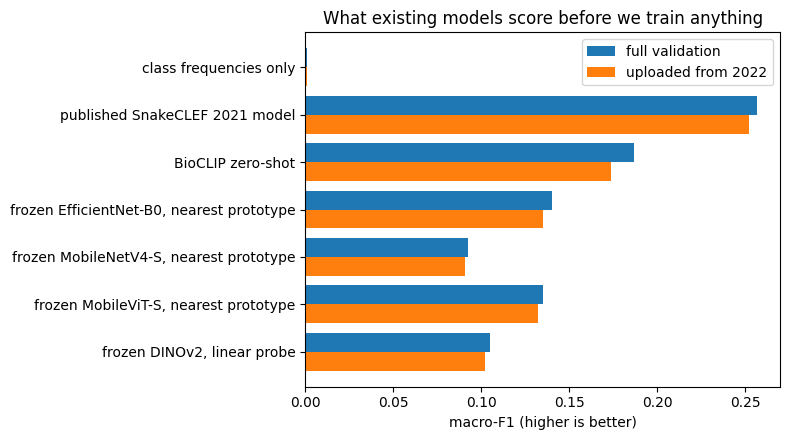

In [33]:
species_rows = comparison[comparison["macro_f1"].notna()]
labels = [PLAIN[name] for name in species_rows.index][::-1]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(positions + 0.2, species_rows["macro_f1"][::-1], height=0.4, label="full validation")
ax.barh(positions - 0.2, species_rows["macro_f1_2022"][::-1], height=0.4,
        label="uploaded from 2022")
ax.set_yticks(positions, labels)
ax.set_xlabel("macro-F1 (higher is better)")
ax.set_title("What existing models score before we train anything")
ax.legend()
plt.tight_layout()
plt.show()

## What we found

The table above is this run's own result. In the committed run, guessing from class frequencies (B0)
scored macro-F1 0.001, so any real score is learned from the photo. The published SnakeCLEF model (B1)
scored top-1 0.68 on all validation photos, but it knows only 62 of our 184 species, so it can never
be right on the rest; its macro-F1 was 0.26. BioCLIP (B2) reached 0.19, and the frozen encoders (B3 and
B4) 0.09 to 0.14. The off-the-shelf detector (B5) found a snake with 0.82 precision but missed most of
them (recall 0.22). The response floor (R0) put the right passage in the top three for 40% of questions.
None of this comes close to a model trained for these species, which is why we train one. The appendix
below scores that trained model with the very same function.

## Appendix: our final trained model, scored with the same function

To put the baselines in context, we score our final trained model (the saved run on the Kaggle dataset
`serpentguard-m3-run-final`, saved under `H1_top1_s1`) with exactly the same `baseline_metrics`
function, on two sets of species. "All 184" is every species. "62 B1 knows" is only the species B1
can name, which is the fair ground for comparing the two. For that set we also give our model a
"closed set" row: it may only answer with those 62 species, as B1 is forced to. The 2022 slice holds
photos uploaded from 2022, which B1 cannot have trained on.

Two checks guard the numbers. The scoring function must reproduce the run's own recorded macro-F1.
And with the labels shuffled it must collapse to chance. This part needs the B1 result from above.

In [34]:
run_root = Path(kagglehub.dataset_download("puneetbajajiitm/serpentguard-m3-run-final"))
final_dir = next(run_root.rglob("val_outputs.npz")).parent
saved = np.load(final_dir / "val_outputs.npz")
logits, labels = saved["species_logits"].astype(np.float64), saved["labels"]
final_val = pd.DataFrame({"path": saved["paths"], "class_id": labels,
                          "genus_id": saved["genus_id"], "family_id": saved["family_id"]})
final_in_2022 = upload_2022_slice(final_val, metadata)
no_counts = np.zeros(taxa.n_classes, dtype=int)  # training counts only feed the tier split
ours = baseline_metrics(final_val, softmax(logits), no_counts, taxa, final_in_2022,
                        {"run": final_dir.name})
b1 = json.loads((OUT / "B1" / "final_metrics.json").read_text())
shared = sorted(b1["coverage"]["covered_class_ids"])
print(f"{len(final_val)} validation photos, {int(final_in_2022.sum())} uploaded from 2022, "
      f"{len(shared)} species shared with B1")

17151 validation photos, 13947 uploaded from 2022, 62 species shared with B1


In [35]:
def per_class_scores(per_class, class_ids):
    """Top-1, mean recall and macro-F1 over the given classes that have validation photos."""
    per_class = {str(k): v for k, v in per_class.items()}  # JSON keys are text
    rows = [per_class[str(c)] for c in class_ids if per_class[str(c)]["support"] > 0]
    support, recall = np.array([r["support"] for r in rows]), np.array([r["recall"] for r in rows])
    return {"top-1": (recall * support).sum() / support.sum(), "mean recall": recall.mean(),
            "macro-F1": np.mean([r["f1"] for r in rows])}

own = json.loads((final_dir / "final_metrics.json").read_text())["head"]["macro_f1"]
assert abs(ours["head"]["macro_f1"] - own) < 1e-9, "must reproduce the run's own macro-F1"
shuffled = final_val.assign(class_id=np.random.default_rng(0).permutation(labels))
control = baseline_metrics(shuffled, softmax(logits), no_counts, taxa, final_in_2022,
                           {"run": "shuffled"})["head"]["macro_f1"]
assert control < 0.02, "with shuffled labels the score must fall to chance"
for model in (ours, b1):  # per-class figures must rebuild each model's own top-1
    for head in (model["head"], model["upload_2022_slice"]["head"]):
        rebuilt = per_class_scores(head["per_class"], range(taxa.n_classes))["top-1"]
        assert abs(rebuilt - head["top1"]) < 1e-9
print(f"checks passed: reproduces the run's macro-F1 {own:.3f}; "
      f"shuffled labels score {control:.3f}")

checks passed: reproduces the run's macro-F1 0.367; shuffled labels score 0.006


Now the comparison table. For "ours, closed set" we take, for each photo of a shared species, the most
likely of the 62 shared species only.

In [36]:
rows = []
settings_2022 = ("uploaded from 2022", final_in_2022, ours["upload_2022_slice"]["head"],
                 b1["upload_2022_slice"]["head"])
for evaluation, keep, o, b in (("full validation", np.ones(len(labels), bool), ours["head"],
                                b1["head"]), settings_2022):
    for model, head in (("ours", o), ("B1", b)):
        rows.append({"evaluation": evaluation, "species": "all 184", "model": model,
                     "macro-F1": head["macro_f1"], "top-1": head["top1"], "top-3": head["top3"]})
        rows.append({"evaluation": evaluation, "species": "62 B1 knows", "model": model,
                     **per_class_scores(head["per_class"], shared)})
    mask = np.isin(labels, shared) & keep
    predicted, truth = np.asarray(shared)[logits[mask][:, shared].argmax(axis=1)], labels[mask]
    rows.append({"evaluation": evaluation, "species": "62 B1 knows", "model": "ours, closed set",
                 "top-1": np.mean(predicted == truth),
                 "mean recall": np.mean([np.mean(predicted[truth == c] == c)
                                         for c in shared if np.any(truth == c)])})
b1_comparison = pd.DataFrame(rows)
b1_comparison.to_csv(OUT / "b1_comparison.csv", index=False)
b1_comparison.set_index(["evaluation", "species", "model"]).round(3)

macro-F1  top-1  top-3  \
evaluation         species     model                                      
full validation    all 184     ours                 0.367  0.622  0.762   
                   62 B1 knows ours                 0.568  0.682    NaN   
                   all 184     B1                   0.257  0.683  0.771   
                   62 B1 knows B1                   0.653  0.801    NaN   
                               ours, closed set       NaN  0.701    NaN   
uploaded from 2022 all 184     ours                 0.357  0.617  0.756   
                   62 B1 knows ours                 0.560  0.679    NaN   
                   all 184     B1                   0.252  0.674  0.767   
                   62 B1 knows B1                   0.637  0.788    NaN   
                               ours, closed set       NaN  0.697    NaN   

                                                 mean recall  
evaluation         species     model                          
full validation    all 184     ours                      NaN  
                   62 B1 knows ours                    0.585  
                   all 184     B1                        NaN  
                   62 B1 knows B1                      0.755  
                               ours, closed set        0.603  
uploaded from 2022 all 184     ours                      NaN  
                   62 B1 knows ours                    0.577  
                   all 184     B1                        NaN  
                   62 B1 knows B1                      0.737  
                               ours, closed set        0.594

On all 184 species the trained model is far ahead of every baseline, and on the 62 species B1 knows
the two models can be compared like for like. In the committed run, B1 scores higher on those 62 (it
was trained on far more snake photos), while our model covers all 184 species and fits on a phone.
Read the table above for this run's own numbers.